### Section 0 - Setup

In [466]:
import pandas as pd
import matplotlib.pyplot as plt
from fredapi import Fred
from dotenv import load_dotenv
import os

In [467]:
#Loads API key from .env file
load_dotenv()
api_key = os.getenv("FRED_API_KEY")
fred = Fred(api_key=api_key)

In [468]:
test_1 = fred.get_series("DGS10", observation_start="2024-01-01", observation_end="2024-01-10")
print(test_1)

2024-01-01     NaN
2024-01-02    3.95
2024-01-03    3.91
2024-01-04    3.99
2024-01-05    4.05
2024-01-08    4.01
2024-01-09    4.02
2024-01-10    4.04
dtype: float64


After importing the relevant packages, I can load the API key from the .env file, and use the fredapi package to connect to the API. After running the second block of code without any errors, I used the get_series function to collect a sample of data between Jan 1-10 2024,from DGS10 for further verification. I can see from the output that it looks consistent with expected yield levels(~4%).

### Section 1 - Data Collection and Validation

In [469]:
try:
    dgs10 = fred.get_series("DGS10", observation_start="1800-01-01")
    dgs10 = dgs10.rename("DGS10")
except Exception as e:
    print(f"Failed to pull DGS10: {e}")

print("Shape:", dgs10.shape)
print(dgs10.head())
print(dgs10.tail())
print("Index type:", type(dgs10.index))
print("Missing values:", dgs10.isna().sum())
print("First 10 missing dates:", dgs10[dgs10.isna()].index[:10].tolist())
print("Date spacing (top 5):")
print(dgs10.index.to_series().diff().value_counts().head())
print("Min/Max:", dgs10.min(), "/", dgs10.max())

dgs10.to_csv("raw_dgs10.csv")

Shape: (16898,)
1962-01-02    4.06
1962-01-03    4.03
1962-01-04    3.99
1962-01-05    4.02
1962-01-08    4.03
Name: DGS10, dtype: float64
2026-10-02    5.28
2026-10-05    5.31
2026-10-06    5.27
2026-10-07    5.28
2026-10-08    5.22
Name: DGS10, dtype: float64
Index type: <class 'pandas.DatetimeIndex'>
Missing values: 720
First 10 missing dates: [Timestamp('1962-02-12 00:00:00'), Timestamp('1962-02-22 00:00:00'), Timestamp('1962-04-20 00:00:00'), Timestamp('1962-05-30 00:00:00'), Timestamp('1962-07-04 00:00:00'), Timestamp('1962-09-03 00:00:00'), Timestamp('1962-10-12 00:00:00'), Timestamp('1962-11-06 00:00:00'), Timestamp('1962-11-12 00:00:00'), Timestamp('1962-11-22 00:00:00')]
Date spacing (top 5):
1 days    13518
3 days     3379
Name: count, dtype: int64
Min/Max: 0.52 / 15.84


What we can see from the output:

- I set `observation_start` to 1800-01-01 (deliberately before any real data) so FRED reveals the true start date rather than one I assume - this confirms DGS10 begins 1962-01-02. I rename it to "DGS10" for clarity in later steps.

- Shape (16,860 rows) matches ~64 years of daily, business day data. Index and values are datetime and float, as expected. The 719 missing values are all US federal holidays (confirmed by the first 10 dates), not a data issue.

- Date spacing only shows 1-day and 3-day gaps because `.diff()` checks the index, not values: weekends are excluded from the index (a real 3-day gap), while holidays still exist as rows with a NaN value (no gap at all).

- The min/max values are plausible values so we can confirm that there are no sentinel values. 

In [470]:
try:
    dgs2 = fred.get_series("DGS2", observation_start="1800-01-01")
    dgs2 = dgs2.rename("DGS2")
except Exception as e:
    print(f"Failed to pull DGS2: {e}")

print("Shape:", dgs2.shape)
print(dgs2.head())
print(dgs2.tail())
print("Index type:", type(dgs2.index))
print("Missing values:", dgs2.isna().sum())
print("First 10 missing dates:", dgs2[dgs2.isna()].index[:10].tolist())
print("Date spacing (top 5):")
print(dgs2.index.to_series().diff().value_counts().head())
print("Min/Max:", dgs2.min(), "/", dgs2.max())

dgs2.to_csv("raw_dgs2.csv")

Shape: (13138,)
1976-06-01    7.26
1976-06-02    7.23
1976-06-03    7.22
1976-06-04    7.12
1976-06-07    7.09
Name: DGS2, dtype: float64
2026-10-02    4.83
2026-10-05    4.84
2026-10-06    4.79
2026-10-07    4.77
2026-10-08    4.75
Name: DGS2, dtype: float64
Index type: <class 'pandas.DatetimeIndex'>
Missing values: 552
First 10 missing dates: [Timestamp('1976-07-05 00:00:00'), Timestamp('1976-09-06 00:00:00'), Timestamp('1976-10-11 00:00:00'), Timestamp('1976-11-02 00:00:00'), Timestamp('1976-11-11 00:00:00'), Timestamp('1976-11-25 00:00:00'), Timestamp('1976-12-24 00:00:00'), Timestamp('1977-02-21 00:00:00'), Timestamp('1977-04-08 00:00:00'), Timestamp('1977-05-30 00:00:00')]
Date spacing (top 5):
1 days    10510
3 days     2627
Name: count, dtype: int64
Min/Max: 0.09 / 16.95


The same methods are used for DGS2, so we can see that the data starts mid-1976, 14 years after DGS10. This limits the 10Y-2Y analysis. After some research I can see that this is because 2-year treasury notes weren't issued on a regular schedule until the mid-1970s. All the other values check out, so we can move on from here. 

In [471]:
try:
    dgs3mo = fred.get_series("DGS3MO", observation_start="1800-01-01")
    dgs3mo = dgs3mo.rename("DGS3MO")
except Exception as e:
    print(f"Failed to pull DGS3MO: {e}")

print("Shape:", dgs3mo.shape)
print(dgs3mo.head())
print(dgs3mo.tail())
print("Index type:", type(dgs3mo.index))
print("Missing values:", dgs3mo.isna().sum())
print("First 10 missing dates:", dgs3mo[dgs3mo.isna()].index[:10].tolist())
print("Date spacing (top 5):")
print(dgs3mo.index.to_series().diff().value_counts().head())
print("Min/Max:", dgs3mo.min(), "/", dgs3mo.max())

dgs3mo.to_csv("raw_dgs3mo.csv")

Shape: (11768,)
1981-09-01    17.01
1981-09-02    16.65
1981-09-03    16.96
1981-09-04    16.64
1981-09-07      NaN
Name: DGS3MO, dtype: float64
2026-10-02    4.19
2026-10-05    4.22
2026-10-06    4.21
2026-10-07    4.22
2026-10-08    4.23
Name: DGS3MO, dtype: float64
Index type: <class 'pandas.DatetimeIndex'>
Missing values: 492
First 10 missing dates: [Timestamp('1981-09-07 00:00:00'), Timestamp('1981-10-12 00:00:00'), Timestamp('1981-11-03 00:00:00'), Timestamp('1981-11-11 00:00:00'), Timestamp('1981-11-26 00:00:00'), Timestamp('1981-12-09 00:00:00'), Timestamp('1981-12-25 00:00:00'), Timestamp('1982-01-01 00:00:00'), Timestamp('1982-02-12 00:00:00'), Timestamp('1982-02-15 00:00:00')]
Date spacing (top 5):
1 days    9414
3 days    2353
Name: count, dtype: int64
Min/Max: 0.0 / 17.01


This is the same check as we did before for DGS10 and DGS2, all the values check out perfectly, and we can see that the data started in 1981, a lot later than the other two, so this will limit our comparision capabilities, as the date ranges differ too much. However, I would still like to use the 10Y-3MO comparision as it's the version the NY Fed's own recession model actually uses and has been shown to outperform 10Y-2Y empirically. 

In [472]:
try:
    usrec = fred.get_series("USREC", observation_start="1800-01-01")
    usrec = usrec.rename("USREC")
except Exception as e:
    print(f"Failed to pull USREC: {e}")

print("Shape:", usrec.shape)
print(usrec.head())
print(usrec.tail())
print("Index type:", type(usrec.index))
print("Missing values:", usrec.isna().sum())
print("Unique values:", usrec.unique())
print("Date spacing (top 5):")
print(usrec.index.to_series().diff().value_counts().head())

usrec.to_csv("raw_usrec.csv")

Shape: (2062,)
1854-12-01    1.0
1855-01-01    0.0
1855-02-01    0.0
1855-03-01    0.0
1855-04-01    0.0
Name: USREC, dtype: float64
2026-05-01    0.0
2026-06-01    0.0
2026-07-01    0.0
2026-08-01    0.0
2026-09-01    0.0
Name: USREC, dtype: float64
Index type: <class 'pandas.DatetimeIndex'>
Missing values: 0
Unique values: [1. 0.]
Date spacing (top 5):
31 days    1203
30 days     686
28 days     130
29 days      42
Name: count, dtype: int64


USREC goes back to **1854** - NBER's recession dating extends way further than the other three yield series, so this isn't the limiting factor for our date range. No missing values, since it's a monthly series with no daily weekend or holiday gaps. The `[1. 0.]` unique values confirm it's a binary flag, as expected. Date spacing (28–31 days) confirms monthly frequency.

### Section 2 - Exploratory Data Analysis (Raw Series)

Before I combine or transform the four series in any way, Im going to look at each one on its own. This is intentional as it'll be easier to catch something odd like an unexpected large gap, or a suspicious value, if I look at the raw data first instead of after I've merged and reshaped everything. Whatever I decide to do in the wrangling step (Section 3) will be informed by what I actually see here.

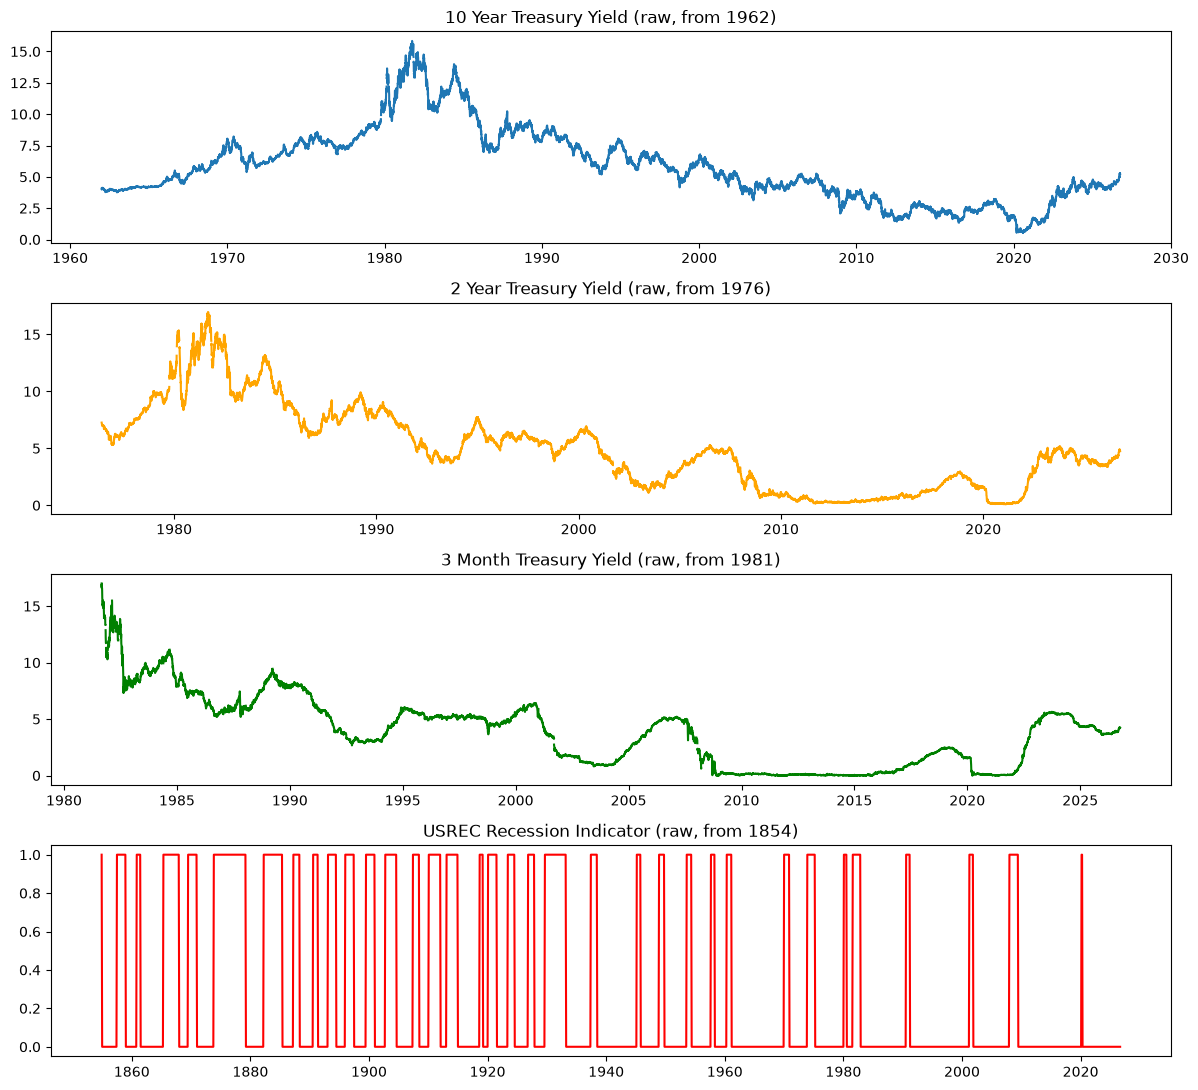

In [473]:
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=False)
axes[0].plot(dgs10.index, dgs10.values)
axes[0].set_title(f"10 Year Treasury Yield (raw, from {dgs10.index.min().year})")
axes[1].plot(dgs2.index, dgs2.values, color="orange")
axes[1].set_title(f"2 Year Treasury Yield (raw, from {dgs2.index.min().year})")
axes[2].plot(dgs3mo.index, dgs3mo.values, color="green")
axes[2].set_title(f"3 Month Treasury Yield (raw, from {dgs3mo.index.min().year})")
axes[3].plot(usrec.index, usrec.values, color="red")
axes[3].set_title(f"USREC Recession Indicator (raw, from {usrec.index.min().year})")
plt.tight_layout()
plt.show()

Before combining the four series, I plotted each one on its own to get a feel for its shape and range. I deliberately didn't share the x-axis across the four subplots; they all started at different points, as we can see in section 1, so sharing one x-axis would have stretched every subplot back to whichever series started earliest, leaving misleading empty space on the others. Each subplot's title showed its actual start year, read directly from the data. There are no large gaps in the data or any unexpected values on all four of the plots, so I can safely move on from here. 

In [474]:
print("DGS10 describe:")
print(dgs10.describe())
print()

print("DGS2 describe:")
print(dgs2.describe())
print()

print("DGS3MO describe:")
print(dgs3mo.describe())
print()

print("USREC describe:")
print(usrec.describe())

DGS10 describe:
count    16178.000000
mean         5.804329
std          2.927308
min          0.520000
25%          3.900000
50%          5.390000
75%          7.530000
max         15.840000
Name: DGS10, dtype: float64

DGS2 describe:
count    12586.000000
mean         4.952199
std          3.650078
min          0.090000
25%          1.720000
50%          4.620000
75%          7.087500
max         16.950000
Name: DGS2, dtype: float64

DGS3MO describe:
count    11276.000000
mean         3.828781
std          3.107306
min          0.000000
25%          0.940000
50%          3.930000
75%          5.580000
max         17.010000
Name: DGS3MO, dtype: float64

USREC describe:
count    2062.000000
mean        0.280795
std         0.449497
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: USREC, dtype: float64


I also check basic summary statistics for each series count, mean, min, max, and quartiles. This is an additional check before moving on. Yields should fall in a plausible range (roughly 0-16% historically), and USREC should only ever be 0 or 1. Anything outside these ranges would flag a data issue worth investigating before I build anything on top of it. As we can see, everything is in range and we can move on to the next section from here.

### Section 3 - Data Wrangling

Before I can compare the yields or calculate a spread, I need all four series lined up on the same timeline. Right now they don't match because the yields are daily and USREC is monthly, and each series starts at a different point in history. This section resamples everything to monthly and combines them into two aligned tables to work with going forward.

In [475]:
monthly_dgs10 = dgs10.resample("MS").mean()
monthly_dgs2 = dgs2.resample("MS").mean()
monthly_dgs3mo = dgs3mo.resample("MS").mean()
monthly_usrec = usrec.resample("MS").last()

- I resampled the daily yield series (10Y, 2Y, 3M) to monthly using `"MS"` 
(represents month-start), which averages each month's daily values into a single number 
and labels it with the first day of that month in one step.
- I used `"MS"` specifically because it already labels each row with the first of the month, matching USREC's own date convention. This can be seen in the data collection and validation of USREC in section 1.
- USREC is already monthly, so I just took `.last()` per month, which takes the last value in that month, and therefore chooses the only value in the month.

In [476]:
df_full = pd.concat([monthly_dgs10, monthly_dgs2, monthly_usrec], axis=1, sort=False)
df_full = df_full.dropna()

df_common = pd.concat([monthly_dgs10, monthly_dgs2, monthly_dgs3mo, monthly_usrec], axis=1, sort=False)
df_common = df_common.dropna()

print(f"df_full   (10Y-2Y only): {df_full.index.min().date()} to {df_full.index.max().date()} ({df_full.shape[0]} months)")
print(f"df_common (10Y-2Y-3M)  : {df_common.index.min().date()} to {df_common.index.max().date()} ({df_common.shape[0]} months)")

df_full   (10Y-2Y only): 1976-06-01 to 2026-09-01 (604 months)
df_common (10Y-2Y-3M)  : 1981-09-01 to 2026-09-01 (541 months)


- I created two separate combined tables instead of one:
  - `df_full` - only 10Y and 2Y, so it keeps the longest possible history (starting in 1976-06-01, where DGS2 begins). This is why `dropna()` was used, as DGS10 starts in 1962, a lot earlier, so we have to use the common months available between the two.
  - `df_common` - includes 3M as well, so `dropna()` truncates it to 1981-09-01 where DGS3MO data actually starts, which is later than 10Y and 2Y.
- I split them this way because merging all three yields into a single table and dropping missing rows would truncate the whole dataset to 3M's shorter history, losing several years of the otherwise valid 10Y-2Y data. `df_full` avoids that, `df_common` exists specifically for a fair 10Y-2Y vs 10Y-3M comparison later, where both spreads need to be tested over the same window.
- I printed out the date range of the two datasets, and how many months they cover. As you can see, df_common has a lot less months that df_full due to the shorter date range.

### Section 4 - Exploratory Data Analysis (Combined Datasets)

Before calculating any spreads, I'm going to check both merged datasets from Section 3, first `df_full` (the main dataset used for the rest of the notebook), then `df_common` (the secondary dataset that also includes DGS3MO for the 10Y-2Y vs 10Y-3MO comparision), to confirm the monthly resampling and series alignment worked correctly.

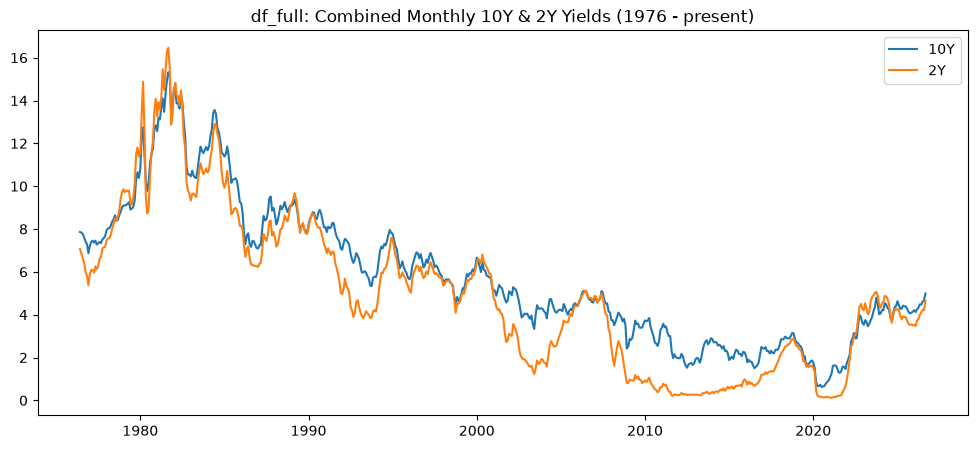

            DGS10        DGS2       USREC
count  604.000000  604.000000  604.000000
mean     5.800883    4.956364    0.096026
std      3.236345    3.652656    0.294872
min      0.623636    0.115263    0.000000
25%      3.392405    1.742500    0.000000
50%      5.087500    4.601632    0.000000
75%      7.856394    7.107395    0.000000
max     15.323810   16.457619    1.000000

Correlation matrix (df_full):
          DGS10      DGS2     USREC
DGS10  1.000000  0.972365  0.206647
DGS2   0.972365  1.000000  0.182331
USREC  0.206647  0.182331  1.000000


In [477]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_full.index, df_full["DGS10"], label="10Y")
ax.plot(df_full.index, df_full["DGS2"], label="2Y")
ax.legend()
ax.set_title("df_full: Combined Monthly 10Y & 2Y Yields (1976 - present)")
plt.show()

print(df_full.describe())
print()
print("Correlation matrix (df_full):")
print(df_full.corr())

- I plotted the 10Y and 2Y yields together using df_full, the main dataset the rest of the notebook is built on. This checks that the monthly resampling and series merge from Section 3 worked correctly. The two lines follow each other closely over time, which is what I'd expect from two treasury yields, so the alignment looks correct. We can also see that the two series have a strong positive relationship using the correlation matrix, as the correlation between the two series is close to 1.

- The summary statistics(using `.describe()`) shows both yields sitting in a reasonable range: DGS10 averages 5.80% (ranging 0.62%-15.32%) and DGS2 averages 4.96% (ranging 0.12%-16.46%). USREC averages 0.096, meaning about 9.6% of months in this sample were recession months. Nothing here looks off, so I can move on to calculating the spread in Section 5.

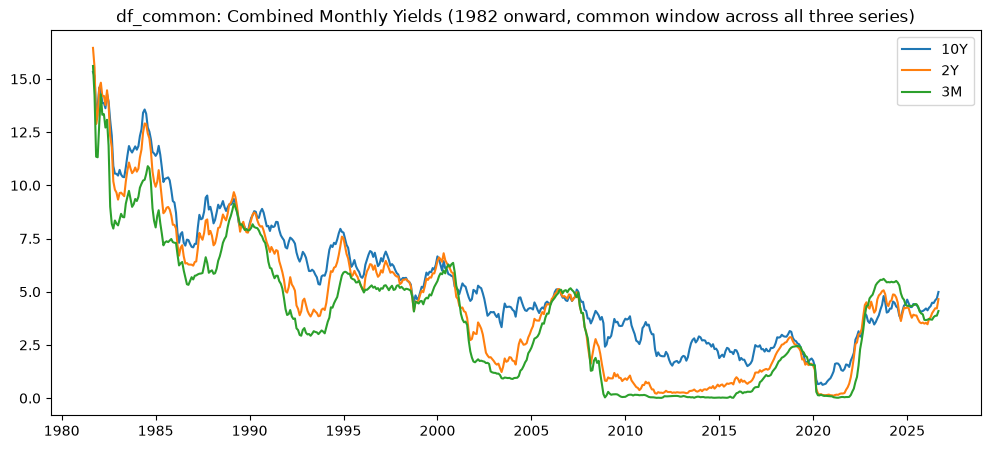

            DGS10        DGS2      DGS3MO       USREC
count  541.000000  541.000000  541.000000  541.000000
mean     5.362241    4.422836    3.831377    0.094270
std      3.047837    3.340383    3.110003    0.292474
min      0.623636    0.115263    0.011429    0.000000
25%      2.912381    1.519048    0.944737    0.000000
50%      4.599545    4.210000    3.950000    0.000000
75%      7.165714    6.276667    5.578000    0.000000
max     15.323810   16.457619   15.607143    1.000000

Correlation matrix:
           DGS10      DGS2    DGS3MO     USREC
DGS10   1.000000  0.967871  0.919045  0.207972
DGS2    0.967871  1.000000  0.981998  0.182016
DGS3MO  0.919045  0.981998  1.000000  0.164979
USREC   0.207972  0.182016  0.164979  1.000000


In [478]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_common.index, df_common["DGS10"], label="10Y")
ax.plot(df_common.index, df_common["DGS2"], label="2Y")
ax.plot(df_common.index, df_common["DGS3MO"], label="3M")
ax.legend()
ax.set_title("df_common: Combined Monthly Yields (1982 onward, common window across all three series)")
plt.show()

print(df_common.describe())
print()
print("Correlation matrix:")
print(df_common.corr())

- I plotted the 10Y, 2Y, and 3M yields together using df_common, the secondary dataset used specifically for the 10Y-2Y vs 10Y-3M comparison later on. This checks that including DGS3MO in the merge and resampling worked correctly. The three lines follow each other closely over time, which is what I'd expect from three treasury yields, so the alignment looks correct. The correlation matrix confirms this, showing all three series have a strong positive relationship with each other (0.92-0.98).

- The summary statistics show all three yields sitting in a reasonable range: DGS10 averages 5.36% (ranging 0.62%-15.32%), DGS2 averages 4.42% (ranging 0.12%-16.46%), and DGS3MO averages 3.83% (ranging 0.01%-15.61%). USREC averages 0.094, meaning about 9.4% of months in this sample were recession months. Nothing here looks off, so I can move on to calculating both spreads in Section 5.

### Section 5 - Calculating the Spread

In [479]:
df_full["spread_10y2y"] = df_full["DGS10"] - df_full["DGS2"]

df_common["spread_10y2y"] = df_common["DGS10"] - df_common["DGS2"]
df_common["spread_10y3m"] = df_common["DGS10"] - df_common["DGS3MO"]

print("10Y-2Y spread(1976-06-01):")
print(df_full["spread_10y2y"].describe())
print()
print("10Y-2Y and 10Y-3M speads(1981-09-01):")
print(df_common[["spread_10y2y", "spread_10y3m"]].describe())

10Y-2Y spread(1976-06-01):
count    604.000000
mean       0.844518
std        0.909221
min       -2.135714
25%        0.191534
50%        0.778500
75%        1.467087
max        2.834211
Name: spread_10y2y, dtype: float64

10Y-2Y and 10Y-3M speads(1981-09-01):
       spread_10y2y  spread_10y3m
count    541.000000    541.000000
mean       0.939405      1.530863
std        0.860115      1.240391
min       -1.133810     -1.734545
25%        0.253478      0.546522
50%        0.831500      1.579565
75%        1.561818      2.543636
max        2.834211      4.146190


I calculated the 10Y-2Y yield spread by making use of vectorised operations and simply substracting DGS10 by DGS2. I did this on both `df_full` and `df_common`, since I need a matching 10Y-2Y version on `df_common` for a fair comparison against the 10Y-3M spread later in the notebook. The `.describe()` prints are just a way to briefly check that the numbers look reasonable before moving on.

### Section 6 - Identifying Inversion Events

I will now create a function that takes in a spread series as a parameter and returns information on inversions detected in the spread series. I'm writing the code to not only detect when the inversions begin, but also how long they lasted. So I can see how many inversion periods there were from 1976-06-01 - present and from 1981-09-01 - present.  

In [480]:
def find_inversions(spread_series):
    results = []
    in_inversion = False
    start_date = None
    duration = 0
    min_spread = 0

    for date, value in spread_series.items():
        is_negative = value < 0

        if is_negative and not in_inversion:
            start_date = date
            duration = 1
            min_spread = value
            in_inversion = True
        elif is_negative and in_inversion:
            duration += 1
            min_spread = min(min_spread, value)
        elif not is_negative and in_inversion:
            results.append({
                "start_date": start_date,
                "duration_months": duration,
                "min_spread": min_spread,
            })
            in_inversion = False

    if in_inversion:
        results.append({
            "start_date": start_date,
            "duration_months": duration,
            "min_spread": min_spread,
        })

    return pd.DataFrame(results)


`find_inversions` goes through the spread month by month and records each inversion event:

- Detects when the spread crosses from positive to negative to flag the start of the inversion.
- While inverted, it tracks `duration_months` (consecutive negative months) and `min_spread` (lowest value reached in the inversion).
- Records the inversion once it ends, since that's when duration and min_spread are final.
- Handles the case where the series ends while still inverted, so the last inversion isn't dropped, and still included.
- Returns a pandas DataFrame (`start_date`, `duration_months`, `min_spread`) instead of just a list of dates, used later to test whether deeper inversions predict better.

In [481]:
inv_10y2y = find_inversions(df_full["spread_10y2y"])
inv_10y2y_common = find_inversions(df_common["spread_10y2y"])
inv_10y3m_common = find_inversions(df_common["spread_10y3m"])

print("10Y-2Y inversions (full history, 1976-present):")
print(inv_10y2y.to_string())
print()

print("10Y-2Y inversions (common window, 1981-present):")
print(inv_10y2y_common.to_string())
print()

print("10Y-3M inversions (common window, 1981-present):")
print(inv_10y3m_common.to_string())

10Y-2Y inversions (full history, 1976-present):
   start_date  duration_months  min_spread
0  1978-09-01               20   -2.135714
1  1980-09-01               14   -1.357500
2  1982-02-01                5   -0.397778
3  1989-01-01                6   -0.321818
4  1989-08-01                2   -0.094000
5  1990-03-01                1   -0.038182
6  1998-06-01                1   -0.023636
7  2000-02-01               11   -0.413158
8  2006-02-01                2   -0.099474
9  2006-06-01               10   -0.145238
10 2007-05-01                1   -0.020000
11 2022-07-01               26   -0.929000

10Y-2Y inversions (common window, 1981-present):
   start_date  duration_months  min_spread
0  1981-09-01                2   -1.133810
1  1982-02-01                5   -0.397778
2  1989-01-01                6   -0.321818
3  1989-08-01                2   -0.094000
4  1990-03-01                1   -0.038182
5  1998-06-01                1   -0.023636
6  2000-02-01               11   -0.413158

- Most inversions are short and shallow (1-2 months, min spread barely below zero), while a handful stand out as long and deep. For example, 1978-09 (20mo, -2.14)  and 2022-07 (26mo, -0.93) for 10Y-2Y, and 2022-11 (25mo, -1.73) for 10Y-3M.

- There is a limitation with this method: 
    - The very first row of each series has no prior month to compare against, so the function defaults to treating it as "not negative before".
    - If the spread happens to already be negative on that very first row, it gets flagged as an inversion start, but this could just mean the spread was already negative before my data begins, so technically the date flagged wasn't an inversion start.
    - Both the 10Y-2Y and 10Y-3M spreads show an inversion start at 1981-09-01, exactly where df_common begins. For 10Y-2Y, df_full shows this inversion actually started 1980-09-01, with the next one starting in 1982-02-01. So 1981-09-01 isn't a real start, just where df_common picks up an inversion already in progress. For 10Y-3M, there's no way to verify the start of the inversion, since DGS3MO itself only starts 1981-09-01 so there's no earlier data to look back at.

- I'm moving on past this limitation rather than trying to work around data I don't have access to, so this is just something to take note of when concluding the results.

### Section 7 - Inversions vs recesssions

In [482]:
def find_recession_starts(usrec_series):
    recession_dates = []
    was_in_recession_last_month = False

    for date, value in usrec_series.items():
        is_in_recession_this_month = value == 1
        if is_in_recession_this_month and not was_in_recession_last_month:
            recession_dates.append(date)
        was_in_recession_last_month = is_in_recession_this_month

    return pd.DatetimeIndex(recession_dates)

recession_starts = find_recession_starts(monthly_usrec)

print(f"Recession start dates (detected from full {monthly_usrec.index.min().year}+ history, to avoid boundary artifacts):")
print(list(recession_starts))

Recession start dates (detected from full 1854+ history, to avoid boundary artifacts):
[Timestamp('1854-12-01 00:00:00'), Timestamp('1857-07-01 00:00:00'), Timestamp('1860-11-01 00:00:00'), Timestamp('1865-05-01 00:00:00'), Timestamp('1869-07-01 00:00:00'), Timestamp('1873-11-01 00:00:00'), Timestamp('1882-04-01 00:00:00'), Timestamp('1887-04-01 00:00:00'), Timestamp('1890-08-01 00:00:00'), Timestamp('1893-02-01 00:00:00'), Timestamp('1896-01-01 00:00:00'), Timestamp('1899-07-01 00:00:00'), Timestamp('1902-10-01 00:00:00'), Timestamp('1907-06-01 00:00:00'), Timestamp('1910-02-01 00:00:00'), Timestamp('1913-02-01 00:00:00'), Timestamp('1918-09-01 00:00:00'), Timestamp('1920-02-01 00:00:00'), Timestamp('1923-06-01 00:00:00'), Timestamp('1926-11-01 00:00:00'), Timestamp('1929-09-01 00:00:00'), Timestamp('1937-06-01 00:00:00'), Timestamp('1945-03-01 00:00:00'), Timestamp('1948-12-01 00:00:00'), Timestamp('1953-08-01 00:00:00'), Timestamp('1957-09-01 00:00:00'), Timestamp('1960-05-01 00:00:

In this code cell, I've used the same approach as `inversion_starts`, except here I'm checking `value == 1` instead of `value < 0`. I flag a date only when its month is in recession but the month before wasn't, so a multi-month recession only counts once. 

I ran this function on `monthly_usrec` (untrimmed, back to 1854) instead of `df_full["USREC"]` or `df_common["USREC"]`, which are truncated to 1976/1981. Otherwise the 1981-82 recession, already occuring when df_common's data begins, would be misdetected as its starting right at that boundary.  This is the same limitation as in Section 6, just more likely to bite here, since df_common's cutoff isn't a real-world boundary. This is because the only reason df_common's data only reaches back to 1981 is because DGS3MO happened to start there.

In [483]:
def evaluate_inversions(inversion_dates, recession_dates, lag_months, data_end_date):
    hits = 0
    false_alarms = 0
    excluded_censored = 0
    for inv_date in inversion_dates:
        window_end = inv_date + pd.DateOffset(months=lag_months)
        if window_end > data_end_date:
            excluded_censored += 1
            continue
        
        matched = False
        for rec_date in recession_dates:
            if rec_date > inv_date and rec_date <= window_end:
                matched = True
                break
            
        if matched:
            hits += 1
        else:
            false_alarms += 1
    return hits, false_alarms, excluded_censored

lag_windows = [6, 9, 12, 18, 24]

print(f"Main Analysis: 10Y-2Y spread, full history ({df_full.index.min().year}-{df_full.index.max().year})")
for lag in lag_windows:
    hits, false_alarms, excluded = evaluate_inversions(inv_10y2y["start_date"], recession_starts, lag, df_full.index.max())
    total = hits + false_alarms
    if total > 0:
        hit_rate = hits / total
    else:
        hit_rate = float("nan")
    if excluded > 0:
        note = f" ({excluded} too recent to resolve, excluded)"
    else:
        note = ""
    print(f"Lag {lag}mo --> hits: {hits}, false alarms: {false_alarms}, hit rate: {hit_rate}{note}")

Main Analysis: 10Y-2Y spread, full history (1976-2026)
Lag 6mo --> hits: 1, false alarms: 11, hit rate: 0.08333333333333333
Lag 9mo --> hits: 2, false alarms: 10, hit rate: 0.16666666666666666
Lag 12mo --> hits: 4, false alarms: 8, hit rate: 0.3333333333333333
Lag 18mo --> hits: 6, false alarms: 6, hit rate: 0.5
Lag 24mo --> hits: 9, false alarms: 3, hit rate: 0.75


- `evaluate_inversions` checks that for each inversion, whether a recession started within a given number of months (the lag window). I tested five lag windows (6, 9, 12, 18, 24 months) since the right amount of time to wait isn't obvious, and the result can look very different depending on it.

- Terminology I'm using throughout this section:
    - **hit** - an inversion followed by a real recession within the lag window.
    - **false alarm** - an inversion with no recession in that window
    - **hit rate** - hits / (hits + false alarms), the percentage of inversions that were hits, and not false alarms.
    - **censored** - an inversion too recent to judge yet (the lag window would go past the end of my data, so the true outcome isn't known).

- I excluded censored inversions from both hits and false alarms, rather than guessing. If an inversion happened last year and I'm using a 24-month window, I'd need data from a year in the future to know if a recession followed, so counting it either way would be like making up an outcome.

- I wrote this as a reusable function rather than repeating the loop, since I plan on using it again later for the 10Y-3M head-to-head comparison, and again inside the bootstrap and permutation test cells further down.

-It is important to note that hit rate only answers "of the alarms raised, how many were real". It says nothing about recessions that happened with no prior inversion at all, that's a different question, which I will check separately later using recall.

**Results:**

- Hit rate rises sharply with the lag window: 8% at 6 months, 17% at 9, 33% at 12, 50% at 18, and 75% at 24 months. This isn't the yield curve getting more accurate with more time - it shows that recessions haven't typically followed an inversion immediately. A 6-month window likely just doesn't give the mechanism enough time to play out, which matches NY Fed research suggesting a typical lag window closer to 12-18 months.

- All 12 inversions get judged at every single lag window and none were censored, even at 24 months. This means the most recent inversion in the data is more than 2 years old, so every inversion has had enough time to reveal its true outcome.

- At face value, a 75% hit rate at 24 months looks like a fairly strong signal. But with only 12 inversions total, this is a small sample - a handful of different outcomes could swing that percentage a lot. I'm going to check exactly how much uncertainty this introduces with a bootstrap confidence interval later in this section, rather than taking 75% at face value.

In [484]:
print(f"HEAD-TO-HEAD COMPARISON: same date range ({df_common.index.min().year}-{df_common.index.max().year}) for both spreads")
print()
print("10Y-2Y spread -----------------------------------------------------------")
for lag in lag_windows:
    hits, false_alarms, excluded = evaluate_inversions(inv_10y2y_common["start_date"], recession_starts, lag, df_common.index.max())
    total = hits + false_alarms
    if total > 0:
        hit_rate = hits / total
    else:
        hit_rate = float("nan")
        
    if excluded > 0:
        note = f" ({excluded} too recent to resolve, excluded)"
    else:
        note = ""

    print(f"Lag {lag}mo --> hits: {hits}, false alarms: {false_alarms}, hit rate: {hit_rate}{note}")

print()
print("10Y-3M spread -------------------------------------------------------------")
for lag in lag_windows:
    hits, false_alarms, excluded = evaluate_inversions(inv_10y3m_common["start_date"], recession_starts, lag, df_common.index.max())
    total = hits + false_alarms

    if total > 0:
        hit_rate = hits / total
    else:
        hit_rate = float("nan")

    if excluded > 0:
        note = f" ({excluded} too recent to resolve, excluded)"
    else:
        note = ""

    print(f"Lag {lag}mo --> hits: {hits}, false alarms: {false_alarms}, hit rate: {hit_rate}{note}")


HEAD-TO-HEAD COMPARISON: same date range (1981-2026) for both spreads

10Y-2Y spread -----------------------------------------------------------
Lag 6mo --> hits: 1, false alarms: 10, hit rate: 0.09090909090909091
Lag 9mo --> hits: 2, false alarms: 9, hit rate: 0.18181818181818182
Lag 12mo --> hits: 3, false alarms: 8, hit rate: 0.2727272727272727
Lag 18mo --> hits: 4, false alarms: 7, hit rate: 0.36363636363636365
Lag 24mo --> hits: 7, false alarms: 4, hit rate: 0.6363636363636364

10Y-3M spread -------------------------------------------------------------
Lag 6mo --> hits: 1, false alarms: 9, hit rate: 0.1
Lag 9mo --> hits: 3, false alarms: 7, hit rate: 0.3
Lag 12mo --> hits: 4, false alarms: 6, hit rate: 0.4
Lag 18mo --> hits: 6, false alarms: 3, hit rate: 0.6666666666666666 (1 too recent to resolve, excluded)
Lag 24mo --> hits: 6, false alarms: 2, hit rate: 0.75 (2 too recent to resolve, excluded)


- I compared the 10Y-2Y against 10Y-3M using the exact same function(`evaluate_inversions`) from the main analysis.

- This comparison is restricted to 1981 onward for both spreads, since DGS3MO only exists on FRED from 1981. If I compared 10Y-3M against the full 1976-onward `inv_10y2y` instead, I wouldn't actually be testing which spread predicts better, and the sample range would be different. Using `inv_10y2y_common` (the 2Y spread restricted to the 1981+ range) means both spreads are judged on the same history, so any difference in hit rate is actually about the spread itself.

**Results:**

- 10Y-3M has a higher hit rate than 10Y-2Y at every single lag window. This lines up with what NY Fed and SF Fed research found: 10Y-3M has historically been the stronger recession predictor of the two, not just the more commonly cited one.

- 10Y-3M also has a few censored inversions at the longer lag windows (1 excluded at 18 months, 2 at 24 months) that 10Y-2Y doesn't. This means 10Y-3M has had a more recent inversion that hasn't had enough time yet to reveal its true outcome, since it means 10Y-3M's 24-month hit rate (75%) is based on slightly fewer resolved cases than its 18-month one.

- Both spreads still only have a small number of inversions to judge from (11-12 total), so even though 10Y-3M looks consistently ahead here, we don't know if its just noise, which the bootstrap CI later in this section answers.

In [485]:
def evaluate_recall(inversion_dates, recession_dates, lag_months):
    preceded = 0
    for rec_date in recession_dates:
        window_start = rec_date - pd.DateOffset(months=lag_months)
        matched = False
        for inv_date in inversion_dates:
            if (inv_date >= window_start) and (inv_date < rec_date):
                matched = True
                break
        if matched:
            preceded += 1
            
    total = len(recession_dates)
    if total > 0:
        recall = preceded/ total
    else:
        recall = float("nan")
    return preceded, total, recall

recession_starts_in_range = []
for r in recession_starts:
    if r >= df_full.index.min():
        recession_starts_in_range.append(r)
        
print("10Y-2Y spread: recession recall -------------------------------------------------------------")
for lag in lag_windows:
    preceded, total, recall = evaluate_recall(inv_10y2y["start_date"], recession_starts_in_range, lag)
    print(f"Lag {lag}mo --> {preceded}/{total} recessions preceded by an inversion, recall: {recall}")

10Y-2Y spread: recession recall -------------------------------------------------------------
Lag 6mo --> 1/6 recessions preceded by an inversion, recall: 0.16666666666666666
Lag 9mo --> 2/6 recessions preceded by an inversion, recall: 0.3333333333333333
Lag 12mo --> 3/6 recessions preceded by an inversion, recall: 0.5
Lag 18mo --> 5/6 recessions preceded by an inversion, recall: 0.8333333333333334
Lag 24mo --> 5/6 recessions preceded by an inversion, recall: 0.8333333333333334


- This function, `evaluate_recall`, flips the hit rate question: instead of asking "of the inversions, how many led to a recession," it asks "of the recessions, how many had an inversion prior to the recession" This catches a failure that hit rate can't see - a recession with no prior inversion at all. 

- `recession_starts` goes back to 1854, so I filtered to `recession_starts_in_range` to only judge recessions my yield data could actually have caught. so it only looks at data after 1976.

**Results:**

- Recall climbs from 17% at 6 months to 83% at 18-24 months - same pattern as hit rate.

- Recall doesn't improve past 18 months, its at 5/6 recessions, meaning one recession was never preceded by an inversion within 2 years.

In [486]:
import numpy as np

def bootstrap_hit_rate_ci(inversion_dates, recession_dates, lag_months, data_end_date, n_bootstrap=5000, ci=0.95):
    outcomes = []
    for inv_date in inversion_dates:
        window_end = inv_date + pd.DateOffset(months=lag_months)
        if window_end > data_end_date:
            continue
        hit = False
        for rec_date in recession_dates:
            if (rec_date > inv_date) and (rec_date <= window_end):
                hit = True
                break
        outcomes.append(1 if hit else 0)

    outcomes = np.array(outcomes)
    n = len(outcomes)
    if n == 0:
        return None

    rng = np.random.default_rng(42)
    boot_rates = []
    for _ in range(n_bootstrap):
        sample = rng.choice(outcomes, size=n, replace=True)
        boot_rates.append(sample.mean())

    lower = np.percentile(boot_rates, (1 - ci) / 2 * 100)
    upper = np.percentile(boot_rates, (1 + ci) / 2 * 100)
    point_estimate = outcomes.mean()
    return n, point_estimate, lower, upper

print("10Y-2Y spread: hit rate with 95% bootstrap CI -----------------------------------------------------------------")
for lag in lag_windows:
    result = bootstrap_hit_rate_ci(inv_10y2y["start_date"], recession_starts, lag, df_full.index.max())
    if result is not None:
        n, point_estimate, lower, upper = result
        print(f"Lag {lag}mo --> n={n} inversions, hit rate: {point_estimate} (95% CI: {lower}-{upper})")

10Y-2Y spread: hit rate with 95% bootstrap CI -----------------------------------------------------------------


Lag 6mo --> n=12 inversions, hit rate: 0.08333333333333333 (95% CI: 0.0-0.25)
Lag 9mo --> n=12 inversions, hit rate: 0.16666666666666666 (95% CI: 0.0-0.4166666666666667)
Lag 12mo --> n=12 inversions, hit rate: 0.3333333333333333 (95% CI: 0.08333333333333333-0.5833333333333334)
Lag 18mo --> n=12 inversions, hit rate: 0.5 (95% CI: 0.25-0.75)
Lag 24mo --> n=12 inversions, hit rate: 0.75 (95% CI: 0.5-1.0)


- Bootstrapping checks how much my hit rate estimate earlier could deviates, given how few inversions I have(small sample size). I have 12 outcomes, and my hit rate is just the average of those 12. If history had played out slightly differently, that average could easily have come out different too 

- Bootstrapping simulates that by repeatedly resampling my own 12 outcomes, with replacement (so a resample might pick the same outcome twice), recalculating the hit rate each time.

- I do this 5000 times, giving 5000 slightly different simulated hit rates. Cutting off the bottom and top 2.5% of that distribution leaves the middle 95%. That range is the confidence interval. So it will give the range of my true hit rate, rather than a point estimate.

- Censoring is handled the same way as in `evaluate_inversions`, any inversion too recent to have a resolved outcome is excluded before the resampling even begins.

**Results:**

- The confidence intervals are wide at every lag window. At 24 months, the point estimate is 75%, but the CI spans 50-100%. At 6 months, the CI is 0-25%, nearly covering the entire possible range.

- This width is the real takeaway, with only 12 inversions, I can't say the hit rate is confidently 75%. The true rate could be anywhere from 50% to 100%, I just don't have enough data to narrow it down further. This as mentioned earlier is the biggest limitation of this project.

In [487]:
def permutation_test(inversion_dates, recession_dates, lag_months, data_start, data_end,
                     n_permutations=5000):
    hits, false_alarms, _ = evaluate_inversions(inversion_dates, recession_dates, lag_months, data_end)
    total = hits + false_alarms
    if total == 0:
        return None
    real_hit_rate = hits / total
    n_inversions = len(inversion_dates)

    all_months = pd.date_range(data_start, data_end, freq="MS")
    rng = np.random.default_rng(42)

    null_rates = []
    for _ in range(n_permutations):
        fake_dates = pd.DatetimeIndex(rng.choice(all_months, size=n_inversions, replace=False))
        fake_hits, fake_fa, _ = evaluate_inversions(fake_dates, recession_dates, lag_months, data_end)
        fake_total = fake_hits + fake_fa
        if fake_total > 0:
            null_rates.append(fake_hits / fake_total)

    null_rates = np.array(null_rates)
    p_value = (null_rates >= real_hit_rate).mean()
    return real_hit_rate, p_value, null_rates

print("10Y-2Y spread: permutation test----------------------------------------------------------")
print("Null hypothesis: inversions are no better than random dates at predicting recessions.")
print()
for lag in lag_windows:
    result = permutation_test(inv_10y2y["start_date"], recession_starts, lag, df_full.index.min(), df_full.index.max())
    if result is not None:
        real_rate, p_val, null_dist = result
        print(f"Lag {lag}mo -> real hit rate: {real_rate}, p-value: {p_val:.4f} (mean null rate: {null_dist.mean()})")
    else:
        print(f"Lag {lag}mo -> no non-censored inversions to test")

10Y-2Y spread: permutation test----------------------------------------------------------
Null hypothesis: inversions are no better than random dates at predicting recessions.

Lag 6mo -> real hit rate: 0.08333333333333333, p-value: 0.5174 (mean null rate: 0.058557878787878784)
Lag 9mo -> real hit rate: 0.16666666666666666, p-value: 0.2756 (mean null rate: 0.08824868686868688)
Lag 12mo -> real hit rate: 0.3333333333333333, p-value: 0.0422 (mean null rate: 0.11926050505050505)
Lag 18mo -> real hit rate: 0.5, p-value: 0.0118 (mean null rate: 0.18155757575757575)
Lag 24mo -> real hit rate: 0.75, p-value: 0.0000 (mean null rate: 0.23579666666666663)


- A Permutation test checks whether my real hit rate is actually better than what I'd get from pure chance. I generate 5000 fake versions of history by placing 12 random dates on the calendar instead of real inversions, then run those fake dates through the same `evaluate_inversions` used earlier function to see what hit rate random luck alone produces.

- The p-value is the fraction of those 5000 random trials that scored at least as well as my real inversions did. A small p-value means almost no random guess could match the real result. A large p-value means random guessing does just as well, so the real result isn't actually telling me anything.

**Results:**

- At short lag windows (6-9 months), the p-values are quite high (0.52 and 0.28) so the real hit rate isn't distinguishable from random chance at these windows.

- At 12 months the p-value drops to 0.04, and by 18-24 months it's 0.01 and then 0.0000. So  at longer lag windows, the real inversions are doing meaningfully better than random dates, using the common 5 percent signficance level.

- This matches the pattern seen throughout this section; the yield curve doesn't look like a useful signal if you only wait a few months, but becomes a statistically significant one if you wait 12+ months for a recession to show up.

In [488]:
def enrich_inversions_with_outcome(inv_df, recession_dates, lag_months, data_end_date):
    rows = []
    for _, inv in inv_df.iterrows():
        inv_date = inv["start_date"]
        window_end = inv_date + pd.DateOffset(months=lag_months)

        if window_end > data_end_date:
            months_to_recession = None
            outcome = "censored"
        else:
            matching = []
            for r in recession_dates:
                if r > inv_date and r <= window_end:
                    matching.append(r)
                    
            if matching:
                first_recession = min(matching)
                months_to_recession = (first_recession.year - inv_date.year) * 12 + (first_recession.month - inv_date.month)
                outcome = "hit"
            else:
                months_to_recession = None
                outcome = "false alarm"

        rows.append({
            "start_date": inv_date,
            "duration_months": inv["duration_months"],
            "min_spread": round(inv["min_spread"], 3),
            "outcome": outcome,
            "months_to_recession": months_to_recession,
        })
    return pd.DataFrame(rows)

inv_detail = enrich_inversions_with_outcome(inv_10y2y, recession_starts, 24, df_full.index.max())

print("10Y-2Y inversions: full detail (24-month lag window) -------------------------------------")
print(inv_detail.to_string(index=False))

print()
non_censored = inv_detail[inv_detail["outcome"] != "censored"].copy()
if len(non_censored) > 2:
    non_censored["is_hit"] = (non_censored["outcome"] == "hit").astype(int)
    
    print("Do deeper/longer inversions predict better? -----------------------------------------")
    print(f"Median duration (months): hits = "
          f"{non_censored[non_censored['is_hit']==1]['duration_months'].median()}, "
          f"false alarms = {non_censored[non_censored['is_hit']==0]['duration_months'].median()}")
    print(f"Median depth (min spread): hits = "
          f"{non_censored[non_censored['is_hit']==1]['min_spread'].median()}, "
          f"false alarms = {non_censored[non_censored['is_hit']==0]['min_spread'].median()}")
else:
    print("Not enough non-censored inversions to compare duration/depth patterns.")

10Y-2Y inversions: full detail (24-month lag window) -------------------------------------
start_date  duration_months  min_spread     outcome  months_to_recession
1978-09-01               20      -2.136         hit                 17.0
1980-09-01               14      -1.357         hit                 11.0
1982-02-01                5      -0.398 false alarm                  NaN
1989-01-01                6      -0.322         hit                 19.0
1989-08-01                2      -0.094         hit                 12.0
1990-03-01                1      -0.038         hit                  5.0
1998-06-01                1      -0.024 false alarm                  NaN
2000-02-01               11      -0.413         hit                 14.0
2006-02-01                2      -0.099         hit                 23.0
2006-06-01               10      -0.145         hit                 19.0
2007-05-01                1      -0.020         hit                  8.0
2022-07-01               26      

- I compared the duration and depth of inversions that turned into hits and false alarms, to check whether more severe inversions (longer, deeper) are more reliable signals, as opposed to every inversion counting the same regardless of severity.

**Results:**

- There was no clear pattern. Median duration is nearly identical between hits (6 months) and false alarms (5 months). Median depth actually runs the opposite way to what I'd expect - false alarms were deeper on average (-0.398) than hits (-0.145).

- The clearest example: the 2022-07 inversion is both the longest (26 months) and deepest (-0.929) in the whole table, yet it was a false alarm. While several hits ( 2006-02, 2007-05) were short and shallow, and a recession came after.

- Based on this sample, severity of the inversion doesn't predict whether it's a reliable signal, a brief, shallow inversion was just as likely to precede a recession as a long, deep one.